# Collated Figures — MOC depth plot

This notebook reproduces the basin MOC (Meridional Overturning Circulation) depth plot from the iCESM1.2-ITPCAS workflow. Run the cells top-to-bottom.

In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import CESM122_PI_PATH, CESM122_PLIO_PATH, FIG_DIR, HADCM3_BASIN_PATH, HADCM3_PI_VW_PATH, HADCM3_PLIO_VW_PATH, ICESM12_PI_VVEL_PATH, ICESM12_PLIO_MASK_PATH, ICESM12_PLIO_VVEL_PATH, ICESM13_PI_MOC_PATH, ICESM13_PLIO_MOC_PATH
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

def layer_edges_from_centres(depth):
    """Layer boundaries (m) from level centres that sit midway between them, starting at the surface."""
    depth = np.asarray(depth, dtype=float).reshape(-1)
    edges = np.zeros(depth.size + 1)
    for k in range(depth.size):
        edges[k + 1] = 2 * depth[k] - edges[k]
    return edges

def model_bathymetry_from_wet_cells(depth, wet_by_lat):
    """Deepest wet cell boundary in each latitude column (depth increases downwards)."""
    depth = np.asarray(depth, dtype=float).reshape(-1)
    wet_by_lat = np.asarray(wet_by_lat, dtype=bool)
    if depth.size < 2 or wet_by_lat.ndim != 2 or wet_by_lat.shape[0] != depth.size:
        raise ValueError('Expected a depth-by-latitude wet-cell mask and at least two depths')
    edges = layer_edges_from_centres(depth)
    deepest = np.where(wet_by_lat, np.arange(depth.size)[:, None], -1).max(axis=0)
    bathymetry = np.full(wet_by_lat.shape[1], np.nan)
    valid = deepest >= 0
    bathymetry[valid] = edges[deepest[valid] + 1]
    return bathymetry

def shade_below_model_bathymetry(axis, latitude, bathymetry, bottom):
    """Cover model values below the seafloor without colouring other missing data."""
    latitude = np.asarray(latitude, dtype=float).reshape(-1)
    bathymetry = np.asarray(bathymetry, dtype=float).reshape(-1)
    if latitude.shape != bathymetry.shape:
        raise ValueError('Latitude and bathymetry must have the same shape')
    finite_x = np.flatnonzero(np.isfinite(latitude))
    if finite_x.size == 0:
        return
    # Work in cell edges so even a single shallow column has a shaded width.
    positions = np.arange(latitude.size)
    x = np.interp(positions, finite_x, latitude[finite_x])
    if finite_x.size > 1:
        left_step = (latitude[finite_x[1]] - latitude[finite_x[0]]) / (finite_x[1] - finite_x[0])
        right_step = (latitude[finite_x[-1]] - latitude[finite_x[-2]]) / (finite_x[-1] - finite_x[-2])
    else:
        left_step = right_step = 1.0
    x[:finite_x[0]] = latitude[finite_x[0]] + left_step * (positions[:finite_x[0]] - finite_x[0])
    x[finite_x[-1] + 1:] = latitude[finite_x[-1]] + right_step * (positions[finite_x[-1] + 1:] - finite_x[-1])
    edges = np.empty(latitude.size + 1)
    if latitude.size > 1:
        edges[1:-1] = (x[:-1] + x[1:]) / 2
    edges[0] = x[0] - left_step / 2
    edges[-1] = x[-1] + right_step / 2
    cell_x = np.column_stack((edges[:-1], edges[1:])).ravel()
    cell_depth = np.repeat(bathymetry, 2)
    wet = np.isfinite(latitude) & np.isfinite(bathymetry) & (bathymetry < bottom)
    axis.fill_between(cell_x, cell_depth, bottom, where=np.repeat(wet, 2),
                      facecolor='#d3d3d3', edgecolor='none', zorder=3)

# -----------------------------
# USER CONFIGURATION (edit paths as needed)
# -----------------------------
DATASET_PATH = ICESM12_PLIO_VVEL_PATH
MASK_PATH = ICESM12_PLIO_MASK_PATH

# Choose basin: 'atlantic' or 'pacific'
BASIN = 'atlantic'

# Average over the last N time steps
NUM_TIME_STEPS_TO_AVERAGE = 12

# Plot styling
LEVELS = np.arange(-20, 41, 2)
CLIM_RANGE = [-30, 60]
EARTH_RADIUS_M = 6_371_000.0

In [2]:
# Helper functions and data loading
def basin_selector(mask_da, basin):
    basin = basin.lower()
    if basin == 'pacific':
        return (mask_da > 0) & (mask_da < 4)
    if basin == 'atlantic':
        return (mask_da > 5) | (mask_da == 1)
    raise ValueError("BASIN must be either 'atlantic' or 'pacific'.")

def infer_layer_thickness_m(z_centers_cm):
    return np.diff(layer_edges_from_centres(np.asarray(z_centers_cm, dtype=float) / 100.0))

def infer_zonal_width_m(ulat_da, ulong_da):
    lat_rad = np.deg2rad(np.asarray(ulat_da, dtype=float))
    lon_rad = np.deg2rad(np.asarray(ulong_da, dtype=float))
    lon_step = np.roll(lon_rad, -1, axis=1) - lon_rad
    lon_step = (lon_step + np.pi) % (2 * np.pi) - np.pi
    lon_step = np.abs(lon_step)
    return EARTH_RADIUS_M * np.cos(lat_rad) * lon_step

# Load datasets
vvel_ds = xr.open_dataset(DATASET_PATH, use_cftime=True)
mask_ds = xr.open_dataset(MASK_PATH)

# Convert velocity to m/s (assumes input in cm/s) and extract coords
vvel = vvel_ds['VVEL'] / 100.0
z_t = vvel_ds['z_t']
ulat = vvel_ds['ULAT']
ulong = vvel_ds['ULONG']
region_mask = mask_ds['REGION_MASK']

# Derived grid metrics
z_t_m = z_t.values / 100.0
z_bot_m = layer_edges_from_centres(z_t_m)[1:]  # the cumulative sum applies at each layer's bottom
dz_m = xr.DataArray(infer_layer_thickness_m(z_t.values), coords={'z_t': z_t}, dims=('z_t',))
dx_m = xr.DataArray(infer_zonal_width_m(ulat.values, ulong.values), coords=ulat.coords, dims=ulat.dims)
latitude_1d = ulat.mean(dim='nlon', skipna=True)

# Select basin mask
mask = basin_selector(region_mask, BASIN)

# Compute time-averaged transport and MOC (Sv)
num_time = vvel.sizes['time']
start_idx = max(0, num_time - NUM_TIME_STEPS_TO_AVERAGE)
vvel_mean = vvel.isel(time=slice(start_idx, None)).mean(dim='time')
transport = vvel_mean * dz_m * dx_m
transport = xr.where(np.isfinite(transport), transport, 0)
transport_basin = transport.where(mask)
moc_calc = transport_basin.sum(dim='nlon', skipna=True).cumsum(dim='z_t') / 1e6
# The MOC is zero-filled below the seafloor, so retain the original wet-cell mask.
wet_icesm12 = (vvel_mean.notnull() & (vvel_mean != 0)).where(mask, False).any(dim='nlon')
bathy_icesm12 = model_bathymetry_from_wet_cells(z_t_m, wet_icesm12.values)

print(f"Computed {BASIN.upper()} MOC from {num_time - start_idx} time steps (indices {start_idx} to {num_time - 1}).")
print(f"MOC min: {np.nanmin(moc_calc.values):.2f} Sv")
print(f"MOC max: {np.nanmax(moc_calc.values):.2f} Sv")

Computed ATLANTIC MOC from 12 time steps (indices 0 to 11).
MOC min: -13.47 Sv
MOC max: 50.14 Sv


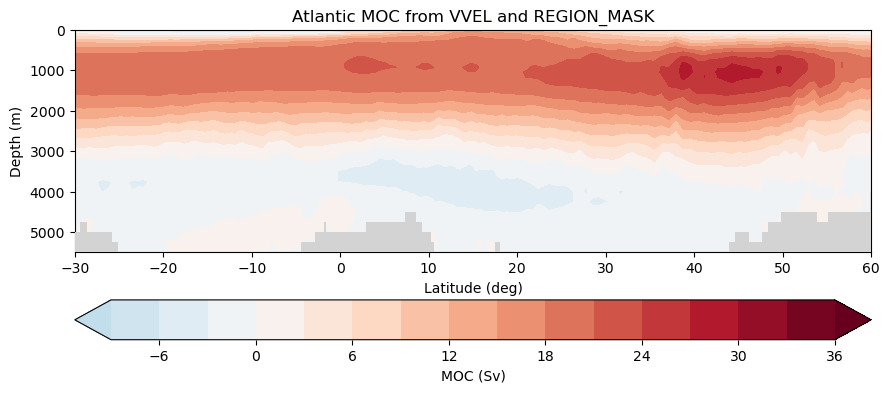

In [3]:
# Plot the selected basin MOC in depth space (this is the figure you requested)
valid_lat = np.isfinite(latitude_1d.values)
lat_valid = latitude_1d.values[valid_lat]
moc_valid = moc_calc[:, valid_lat].values

plt.figure(figsize=(9, 4))
cmap = plt.cm.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=-36, vmax=36)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))
plt.contourf(lat_valid, z_bot_m, moc_valid, levels=np.arange(-9, 39, 3), cmap=cmap, vmin=-36, vmax=36, extend='both')
shade_below_model_bathymetry(plt.gca(), lat_valid, bathy_icesm12[valid_lat], z_bot_m.max())
cb = plt.colorbar(orientation='horizontal', label='MOC (Sv)')
plt.axis([lat_valid.min(), lat_valid.max(), z_bot_m.max(), 0])
plt.xlim(-30, 60)
plt.xlabel('Latitude (deg)')
plt.ylabel('Depth (m)')
plt.title(f"{BASIN.title()} MOC from VVEL and REGION_MASK")
plt.tight_layout()
# Optional: save figure to PNG alongside inline display
plt.show()

# HadCM3 — MOC depth plot

Reproduce the MOC depth figure from the HadCM3 dataset. Input paths are set in `paths.py`.

Loading iCESM1.3 dataset to extract basin boundaries...

iCESM1.3 ATLANTIC basin geographic bounds:
  Latitude:  -83.2° to 90.0°
  Longitude: 0.0° to 360.0°

Loading HadCM3 dataset...
<xarray.Dataset>
Dimensions:      (depth_1: 20, latitude_1: 143, longitude_1: 288, bnds: 2,
                  depth: 19, latitude: 144, longitude: 288)
Coordinates:
  * depth_1      (depth_1) float32 5.0 15.0 25.0 ... 4.577e+03 5.192e+03
  * latitude_1   (latitude_1) float32 -88.75 -87.5 -86.25 ... 86.25 87.5 88.75
  * longitude_1  (longitude_1) float32 0.625 1.875 3.125 ... 356.9 358.1 359.4
    t            object ...
  * depth        (depth) float32 10.0 20.0 30.0 ... 3.654e+03 4.27e+03 4.885e+03
  * latitude     (latitude) float32 -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * longitude    (longitude) float32 0.0 1.25 2.5 3.75 ... 356.2 357.5 358.8
Dimensions without coordinates: bnds
Data variables:
    field704     (depth_1, latitude_1, longitude_1) float32 ...
    t_bnds       (bnds) object ...
   

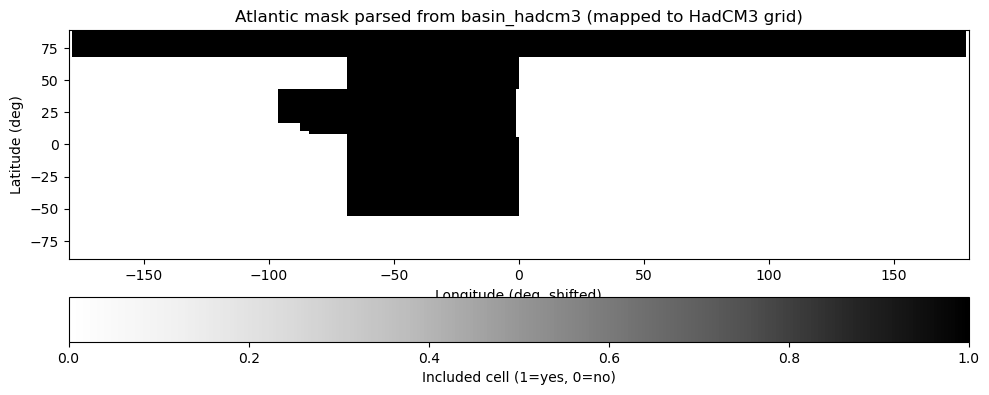

Parsed rows from basin_hadcm3: 144
Mask cells on HadCM3 grid: 11790 / 41184


In [4]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from matplotlib.path import Path # Path for creating custom shape
import numpy.ma as ma # Masked arrays for handling missing data
# -----------------------------
# USER CONFIGURATION
# -----------------------------
HADCM3_DATASET_PATH = HADCM3_PLIO_VW_PATH
ICESM13_DATASET_PATH = ICESM13_PLIO_MOC_PATH

# Choose basin: "atlantic" or "pacific"
BASIN = "atlantic"

def basin_selector_icesm13(mask_da, basin):
    """Basin selector for iCESM1.3 CESM/POP region mask."""
    basin = basin.lower()
    if basin == "pacific":
        return (mask_da > 0) & (mask_da < 4)
    if basin == "atlantic":
        return (mask_da > 5) | (mask_da == 1)
    raise ValueError("BASIN must be either 'atlantic' or 'pacific'.")

# Unit conversions used later:
# field704: cm/s -> m/s
# depth_1: already meters
# HadCM3 grid: 1.25° regular lat/lon grid
def connect_atlantic(lon):
    '''Input: longitude mesh from 0-360, returns longitude mesh from -180 to 180'''
    return (lon + 180) % 360 - 180

def apply_atlantic_mask_2d(array, lat, lon):
    '''
    Input: 2D array (benthic), latitude, and longitude mesh arrays.
    Output: Masked array, with points outside the Atlantic polygon masked.
    '''
    # Define Atlantic polygon coordinates
    atlantic_polygon = Path([
        (-70, 70), (20, 70), (20, 50), (0, 50), (0, 40), (-5, 40), 
        (-5, 20), (20, 20), (20, -90), (-70, -90), 
        (-70, 12.8396), (-90, 12.8396), (-90, 50), (-70, 50)
    ])
    
    # Create a mask based on whether points are inside the polygon
    points = np.column_stack((lon.flatten(), lat.flatten()))
    geographical_mask = atlantic_polygon.contains_points(points).reshape(lat.shape)
    
    if ma.isMaskedArray(array):
        # If the input array is already masked, combine the existing mask with the geographical mask
        original_mask = ma.getmask(array)
        combined_mask = np.logical_or(original_mask, ~geographical_mask)
        masked_array = ma.masked_where(combined_mask, array)
    else:
        # Apply the geographical mask directly to the array
        masked_array = ma.masked_where(~geographical_mask, array)
    
    return masked_array

def apply_atlantic_mask_3d(array, lat, lon, depth):
    '''
    Input: 3D array, Atlantic-connected latitude, longitude mesh arrays and depth 1D arrays.
    Output: Masked array, with points outside the Atlantic polygon masked.
    '''

    # Define Atlantic polygon coordinates
    atlantic_polygon = Path([
        (-70, 70), (20, 70), (20, 50), (0, 50), (0, 40), (-5, 40), 
        (-5, 20), (20, 20), (20, -90), (-70, -90), 
        (-70, 12.8396), (-90, 12.8396), (-90, 50), (-70, 50)
    ])
    depth_values = np.arange(len(depth))
    masked_array = []
    
    for depth in depth_values:
        array_slice = array[depth, :, :] 
        points = np.column_stack((lon.flatten(), lat.flatten()))
        geographical_mask = atlantic_polygon.contains_points(points).reshape(lat.shape)
        if ma.isMaskedArray(array):
            original_mask = ma.getmask(array_slice)
            combined_mask = np.logical_or(original_mask, ~geographical_mask)
            masked_slice = ma.masked_where(combined_mask, array_slice)
        else:
            # Apply the geographical mask directly to the array
            masked_slice = ma.masked_where(~geographical_mask, array_slice)
            
        masked_array.append(masked_slice)
    full_masked_array = ma.stack(masked_array, axis=0)
    return full_masked_array
# Load iCESM1.3 dataset to extract basin boundaries
print("Loading iCESM1.3 dataset to extract basin boundaries...")
icesm13_ds = xr.open_dataset(ICESM13_DATASET_PATH)

region_mask = icesm13_ds["REGION_MASK"]
ulong = icesm13_ds["ULONG"]
ulat = icesm13_ds["ULAT"]

# Get basin mask
basin_mask = basin_selector_icesm13(region_mask, BASIN)

# Extract lat/lon coordinates of basin cells
ulong_basin = ulong.where(basin_mask, drop=False)
ulat_basin = ulat.where(basin_mask, drop=False)

# Find geographic bounds
lat_min = float(ulat_basin.min())
lat_max = float(ulat_basin.max())
lon_min = float(ulong_basin.min())
lon_max = float(ulong_basin.max())

print(f"\niCESM1.3 {BASIN.upper()} basin geographic bounds:")
print(f"  Latitude:  {lat_min:.1f}° to {lat_max:.1f}°")
print(f"  Longitude: {lon_min:.1f}° to {lon_max:.1f}°")
# Load HadCM3 dataset
print("\nLoading HadCM3 dataset...")
hadcm3_ds = xr.open_dataset(HADCM3_DATASET_PATH)
print(hadcm3_ds)

# Extract variables
# field704 is V (meridional velocity) in cm/s
v = hadcm3_ds["field704"] / 100.0  # Convert cm/s to m/s

# Get coordinates
depth_1_hadcm3 = hadcm3_ds["depth_1"].values  # in meters
latitude_1 = hadcm3_ds["latitude_1"].values  # in degrees
longitude_1 = hadcm3_ds["longitude_1"].values  # in degrees

print(f"\nV shape: {v.shape}")
print(f"Depth range: {depth_1_hadcm3.min():.1f} to {depth_1_hadcm3.max():.1f} m")
print(f"Latitude range: {latitude_1.min():.2f} to {latitude_1.max():.2f}°")
print(f"Longitude range: {longitude_1.min():.2f} to {longitude_1.max():.2f}°")
# Calculate dz (vertical cell thickness) from the true layer interfaces.
# W is stored on HadCM3's layer bottoms ('depth'); depth_1 are the layer centres midway between them.
layer_edges_hadcm3 = np.concatenate([[0.0], hadcm3_ds["depth"].values, [2 * depth_1_hadcm3[-1] - hadcm3_ds["depth"].values[-1]]])
dz_values = np.diff(layer_edges_hadcm3)
dz = xr.DataArray(dz_values, coords={"depth_1_hadcm3": depth_1_hadcm3}, dims=["depth_1_hadcm3"])

# Calculate dx from grid spacing
# Grid is 1.25° × 1.25°; zonal cell width shrinks with cos(latitude)
# Earth radius = 6.371e6 m; 1 degree = 111,195 m at equator
deg_to_m = 111195.0
dx = (1.25 * deg_to_m * np.cos(np.deg2rad(latitude_1)))[np.newaxis, :, np.newaxis]  # (1, lat, 1) meters per grid cell

# Broadcast dz to 3D for later transport calculations
dz_3d = dz.values[:, np.newaxis, np.newaxis]  # (depth, 1, 1)

print(f"dz shape: {dz.shape}")
print(f"dz values (m): {dz.values}")
print(f"dx (m): {dx.min():.1f} to {dx.max():.1f}")
# Build basin mask on HadCM3 grid using apply_atlantic_mask_3d function
from matplotlib.path import Path
from scipy.spatial import cKDTree

def shift_lon_to_continuous(lon_values):
    return ((np.asarray(lon_values) + 180.0) % 360.0) - 180.0

# Create lat/lon meshgrids for masking
lat_2d, lon_2d = np.meshgrid(latitude_1, shift_lon_to_continuous(longitude_1), indexing='ij')

# Apply the 3D Atlantic mask function to a dummy field so the mask reflects geometry only
mask_probe_3d = np.ones_like(v.values, dtype=np.float32)
v_masked_3d_all = apply_atlantic_mask_3d(mask_probe_3d, lat_2d, lon_2d, depth_1_hadcm3)

# Extract the pure geographic mask (same for all depths since polygon is depth-independent)
basin_mask_hadcm3 = ~v_masked_3d_all.mask[0]
mask_source = "apply_atlantic_mask_3d geometry-only mask"

print(f"Basin mask shape: {basin_mask_hadcm3.shape}")
print(f"Cells in {BASIN.upper()} basin: {basin_mask_hadcm3.sum()} / {basin_mask_hadcm3.size}")
print(f"Mask source: {mask_source}")
# Test the new apply_atlantic_mask_2d function
# Apply it to a sample depth level of V to see how it handles masked arrays

# Select one depth level
v_sample = v.values[0, :, :]  # Surface level

# Create meshgrids for lat/lon
lat_2d, lon_2d = np.meshgrid(latitude_1, shift_lon_to_continuous(longitude_1), indexing='ij')

# Apply mask using the new function
v_masked_2d = apply_atlantic_mask_2d(v_sample, lat_2d, lon_2d)

print(f"V sample shape: {v_sample.shape}")
print(f"V masked (2D) type: {type(v_masked_2d)}")
print(f"V masked (2D) shape: {v_masked_2d.shape}")
print(f"Masked cells: {v_masked_2d.mask.sum()} / {v_masked_2d.size}")
print(f"Data range (before mask): {np.nanmin(v_sample):.6f} to {np.nanmax(v_sample):.6f} m/s")
comp_2d = v_masked_2d.compressed()
print(f"Compressed valid cells: {comp_2d.size}")
if comp_2d.size > 0:
    print(f"Data range (after mask): {np.nanmin(comp_2d):.6f} to {np.nanmax(comp_2d):.6f} m/s")
else:
    print(f"Data range (after mask): No valid data")
    # Test the new apply_atlantic_mask_3d function
# Apply it to the full 3D V field

# Create meshgrids for lat/lon (same as 2D test)
lat_2d, lon_2d = np.meshgrid(latitude_1, connect_atlantic(longitude_1), indexing='ij')

# Apply 3D mask function
v_masked_3d = apply_atlantic_mask_3d(v.values, lat_2d, lon_2d, depth_1_hadcm3)

print(f"\n=== 3D Mask Function Results ===")
print(f"V (3D) original shape: {v.values.shape}")
print(f"V (3D) masked type: {type(v_masked_3d)}")
print(f"V (3D) masked shape: {v_masked_3d.shape}")
print(f"Total masked cells: {v_masked_3d.mask.sum()} / {v_masked_3d.size}")
print(f"Percentage masked: {100 * v_masked_3d.mask.sum() / v_masked_3d.size:.1f}%")
comp_3d = v_masked_3d.compressed()
print(f"Compressed valid cells: {comp_3d.size}")
if comp_3d.size > 0:
    print(f"Data range (after 3D mask): {np.nanmin(comp_3d):.6f} to {np.nanmax(comp_3d):.6f} m/s")
else:
    print(f"Data range (after 3D mask): No valid data")
    # Parse HADCM3 basin index file and plot Atlantic mask on HadCM3 grid
import re

BASIN_HADCM3_PATH = HADCM3_BASIN_PATH
ATLANTIC_BASIN_INDEX = 3  # 1=Indian, 2=Pacific, 3=Atlantic, 4=Combined

with open(BASIN_HADCM3_PATH, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

# Keep only data rows that start with an integer row id.
row_data = []
for line in lines:
    stripped = line.strip()
    if not stripped or stripped.startswith("C"):
        continue
    if not re.match(r"^\d+", stripped):
        continue

    nums = [int(x) for x in re.findall(r"-?\d+", stripped)]
    # Expected format: row_id + 16 integers (4 basins x 2 segments x start/end).
    if len(nums) >= 17:
        row_id = nums[0]
        vals = nums[1:17]
        row_data.append((row_id, vals))

if not row_data:
    raise ValueError("No basin rows were parsed from basin_hadcm3.")

n_rows_file = max(r for r, _ in row_data)
n_cols_file = 288
mask_file = np.zeros((n_rows_file, n_cols_file), dtype=bool)

# Fill Atlantic segments row-by-row.
for row_id, vals in row_data:
    r = row_id - 1  # file row ids are 1-based
    base = (ATLANTIC_BASIN_INDEX - 1) * 4
    segs = vals[base:base + 4]  # [seg1_start, seg1_end, seg2_start, seg2_end]

    for s, e in [(segs[0], segs[1]), (segs[2], segs[3])]:
        if s <= 0 or e <= 0:
            continue

        # Convert from 1-based inclusive indices to 0-based slicing.
        s0 = max(0, s - 1)
        e0 = min(n_cols_file - 1, e - 1)

        if e0 >= s0:
            mask_file[r, s0:e0 + 1] = True
        else:
            # Handle wrapped segment if present.
            mask_file[r, s0:] = True
            mask_file[r, :e0 + 1] = True

# Map file mask rows to HadCM3 latitude dimension.
# The file is regular 1.25-degree indexing with 144 rows; HadCM3 here uses latitude_1 length.
row_map = np.round(np.linspace(0, n_rows_file - 1, len(latitude_1))).astype(int)
mask_hadcm3 = mask_file[row_map, :len(longitude_1)]

lon_shifted = shift_lon_to_continuous(longitude_1)
lon_2d, lat_2d = np.meshgrid(lon_shifted, latitude_1)

plt.figure(figsize=(10, 4))
im = plt.pcolormesh(
    lon_2d,
    lat_2d,
    mask_hadcm3.astype(float),
    shading="auto",
    cmap="Greys",
    vmin=0,
    vmax=1,
)
plt.colorbar(im, orientation="horizontal", pad=0.12, label="Included cell (1=yes, 0=no)")
plt.xlim([-180, 180])
plt.xlabel("Longitude (deg, shifted)")
plt.ylabel("Latitude (deg)")
plt.title("Atlantic mask parsed from basin_hadcm3 (mapped to HadCM3 grid)")
plt.tight_layout()
plt.show()

print(f"Parsed rows from basin_hadcm3: {n_rows_file}")
print(f"Mask cells on HadCM3 grid: {mask_hadcm3.sum()} / {mask_hadcm3.size}")

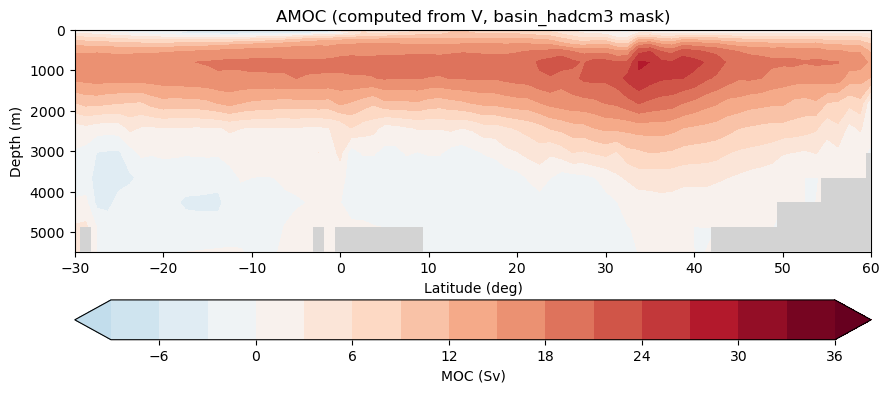

HADCM3-mask MOC range: -69.6 to 47.5 Sv


In [5]:
# Compute and plot MOC using basin_hadcm3 mask
# Rebuild mask_hadcm3 if needed (in case this cell is run independently).
if "mask_hadcm3" not in globals():
    import re

    BASIN_HADCM3_PATH = HADCM3_BASIN_PATH
    ATLANTIC_BASIN_INDEX = 3

    with open(BASIN_HADCM3_PATH, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    row_data = []
    for line in lines:
        stripped = line.strip()
        if not stripped or stripped.startswith("C"):
            continue
        if not re.match(r"^\d+", stripped):
            continue

        nums = [int(x) for x in re.findall(r"-?\d+", stripped)]
        if len(nums) >= 17:
            row_id = nums[0]
            vals = nums[1:17]
            row_data.append((row_id, vals))

    n_rows_file = max(r for r, _ in row_data)
    n_cols_file = 288
    mask_file = np.zeros((n_rows_file, n_cols_file), dtype=bool)

    for row_id, vals in row_data:
        r = row_id - 1
        base = (ATLANTIC_BASIN_INDEX - 1) * 4
        segs = vals[base:base + 4]

        for s, e in [(segs[0], segs[1]), (segs[2], segs[3])]:
            if s <= 0 or e <= 0:
                continue

            s0 = max(0, s - 1)
            e0 = min(n_cols_file - 1, e - 1)
            if e0 >= s0:
                mask_file[r, s0:e0 + 1] = True
            else:
                mask_file[r, s0:] = True
                mask_file[r, :e0 + 1] = True

    row_map = np.round(np.linspace(0, n_rows_file - 1, len(latitude_1))).astype(int)
    mask_hadcm3 = mask_file[row_map, :len(longitude_1)]

# Apply HADCM3 mask to velocity and recompute MOC transport.
mask_hadcm3_3d = np.broadcast_to(mask_hadcm3[np.newaxis, :, :], v.shape)
v_for_transport_hadcm3 = np.nan_to_num(np.where(mask_hadcm3_3d, v.values, 0.0), nan=0.0)
transport_hadcm3 = v_for_transport_hadcm3 * dz_3d * dx
transport_zonal_sum_hadcm3 = np.sum(transport_hadcm3, axis=2)
moc_calc_hadcm3 = np.cumsum(transport_zonal_sum_hadcm3, axis=0)

lat_in_basin_hadcm3 = np.where(mask_hadcm3.any(axis=1))[0]
lat_basin_hadcm3 = latitude_1[lat_in_basin_hadcm3]
moc_plot_hadcm3 = moc_calc_hadcm3[:, lat_in_basin_hadcm3]
wet_hadcm3 = np.isfinite(v.values) & mask_hadcm3[np.newaxis, :, :]
bathy_hadcm3 = model_bathymetry_from_wet_cells(
    depth_1_hadcm3, wet_hadcm3.any(axis=2)[:, lat_in_basin_hadcm3]
)
depth_bot_hadcm3 = layer_edges_hadcm3[1:]  # the cumulative sum applies at each layer's bottom

cmap = plt.cm.get_cmap("RdBu_r")
norm = plt.Normalize(vmin=-36, vmax=36)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))

plt.figure(figsize=(9, 4))
plt.contourf(
    lat_basin_hadcm3,
    depth_bot_hadcm3,
    moc_plot_hadcm3 / 1e6,
    levels=np.arange(-9, 39, 3),
    cmap=cmap,
    vmin=-36,
    vmax=36,
    extend="both",
)
shade_below_model_bathymetry(plt.gca(), lat_basin_hadcm3, bathy_hadcm3, depth_bot_hadcm3.max())
plt.colorbar(orientation="horizontal", label="MOC (Sv)")
plt.axis([lat_basin_hadcm3.min(), lat_basin_hadcm3.max(), depth_bot_hadcm3.max(), 0])
plt.xlim(-30, 60)
plt.xlabel("Latitude (deg)")
plt.ylabel("Depth (m)")
plt.title("AMOC (computed from V, basin_hadcm3 mask)")
plt.tight_layout()
plt.show()

print(f"HADCM3-mask MOC range: {moc_calc_hadcm3.min() / 1e6:.1f} to {moc_calc_hadcm3.max() / 1e6:.1f} Sv")

# iCESM1.3 — MOC depth plot

Reproduce the MOC depth figure from the iCESM1.3 dataset. Input paths are set in `paths.py`.

Computed ATLANTIC MOC from iCESM1.3 dataset.
MOC shape: (1, 60, 394)


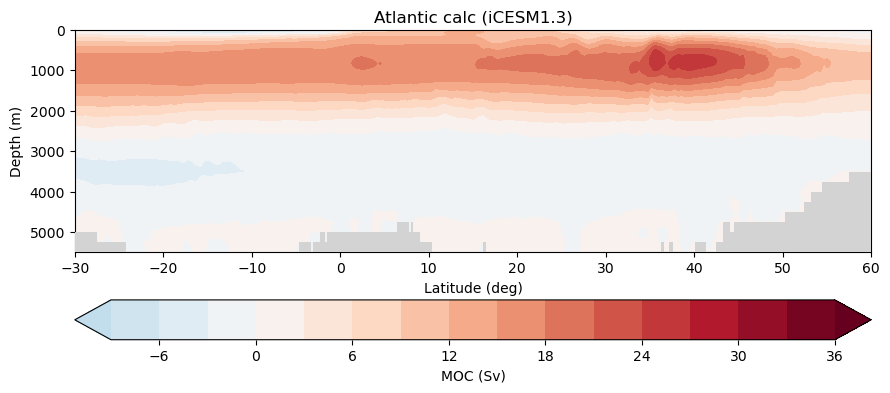

In [6]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# iCESM1.3 dataset path (set in paths.py)
ICESM13_DATASET_PATH = ICESM13_PLIO_MOC_PATH

# Variable mapping used in the iCESM1.3 workflow
ICESM13_VAR_MAP = {
    'vvel': 'VVEL',
    'visop': 'VISOP',
    'dz': 'dz',
    'z_t': 'z_t',
    'ulong': 'ULONG',
    'ulat': 'ULAT',
    'dxu': 'DXU',
    'region_mask': 'REGION_MASK',
    'moc': 'MOC',
    'moc_z': 'moc_z',
    'lat_aux_grid': 'lat_aux_grid',
}

def icesm13_get_required_var(dataset, logical_name):
    name = ICESM13_VAR_MAP[logical_name]
    if name not in dataset:
        raise KeyError(f"Variable '{name}' not found in iCESM1.3 dataset.")
    return dataset[name]

def basin_selector_icesm13(mask_da, basin):
    basin = basin.lower()
    if basin == 'pacific':
        return (mask_da > 0) & (mask_da < 4)
    if basin == 'atlantic':
        return (mask_da > 5) | (mask_da == 1)
    raise ValueError("BASIN must be either 'atlantic' or 'pacific'.")

# Load iCESM1.3 dataset
icesm13_ds = xr.open_dataset(ICESM13_DATASET_PATH)
icesm13_vvel = icesm13_get_required_var(icesm13_ds, 'vvel') / 100.0
# bolus velocity optional
try:
    icesm13_visop = icesm13_get_required_var(icesm13_ds, 'visop') / 100.0
except KeyError:
    icesm13_visop = xr.zeros_like(icesm13_vvel)

icesm13_dz = icesm13_get_required_var(icesm13_ds, 'dz') / 100.0
icesm13_z_t = icesm13_get_required_var(icesm13_ds, 'z_t') / 100.0
icesm13_ulong = icesm13_get_required_var(icesm13_ds, 'ulong')
icesm13_ulat = icesm13_get_required_var(icesm13_ds, 'ulat')
icesm13_dxu = icesm13_get_required_var(icesm13_ds, 'dxu') / 100.0
icesm13_region_mask = icesm13_get_required_var(icesm13_ds, 'region_mask')
icesm13_moc = icesm13_get_required_var(icesm13_ds, 'moc') if 'MOC' in icesm13_ds else None
icesm13_moc_z = icesm13_get_required_var(icesm13_ds, 'moc_z') / 100.0 if 'moc_z' in icesm13_ds else None
icesm13_lat_aux_grid = icesm13_get_required_var(icesm13_ds, 'lat_aux_grid') if 'lat_aux_grid' in icesm13_ds else None

# Compute transport and MOC for selected basin
V = (icesm13_vvel + icesm13_visop) * icesm13_dz * icesm13_dxu
V = xr.where(np.isnan(V), 0, V)
icesm13_mask = basin_selector_icesm13(icesm13_region_mask, BASIN)
V_selected = V.where(icesm13_mask)
icesm13_ulat_selected = icesm13_ulat.where(icesm13_mask)
icesm13_mocz_calc = V_selected.sum(dim='nlon', skipna=True).cumsum(dim='z_t')
icesm13_lats = icesm13_ulat_selected.mean(dim='nlon', skipna=True)
# KMT gives the deepest wet grid cell; finite VVEL also contains dry zeroes.
icesm13_kmt = icesm13_ds['KMT'].values
icesm13_wet_by_lat = np.any(
    (np.arange(icesm13_z_t.size)[:, None, None] < icesm13_kmt[None, :, :])
    & icesm13_mask.values[None, :, :], axis=2
)
bathy_icesm13 = model_bathymetry_from_wet_cells(icesm13_z_t, icesm13_wet_by_lat)
icesm13_z_bot = layer_edges_from_centres(icesm13_z_t.values)[1:]  # the cumulative sum applies at each layer's bottom

print(f"Computed {BASIN.upper()} MOC from iCESM1.3 dataset.")
print(f"MOC shape: {icesm13_mocz_calc.shape}")

# Plot iCESM1.3 MOC in z-space
plt.figure(figsize=(9, 4))
valid_idx = ~np.isnan(icesm13_lats.values)
lats_valid = icesm13_lats.values[valid_idx]
mocz_calc_valid = icesm13_mocz_calc[0, :, valid_idx].values / 1e6
cmap = plt.cm.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=-36, vmax=36)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))
plt.contourf(lats_valid, icesm13_z_bot, mocz_calc_valid, levels=np.arange(-9, 39, 3), cmap=cmap, vmin=-36, vmax=36, extend='both')
shade_below_model_bathymetry(plt.gca(), lats_valid, bathy_icesm13[valid_idx], float(icesm13_z_bot.max()))
plt.colorbar(orientation='horizontal', label='MOC (Sv)')
plt.axis([lats_valid.min(), lats_valid.max(), icesm13_z_bot.max(), 0])
plt.xlim(-30, 60)
plt.xlabel('Latitude (deg)')
plt.ylabel('Depth (m)')
plt.title(f'{BASIN.title()} calc (iCESM1.3)')
plt.tight_layout()
plt.show()

# CESM1.2.2.1 — MOC depth plot

Compute and plot the MOC depth figure from the CESM1.2.2.1 V-velocity field on its native grid. Input paths are set in `paths.py`.

CESM1.2.2.1 plot vmin/vmax (Sv): -35.924976 119.58861


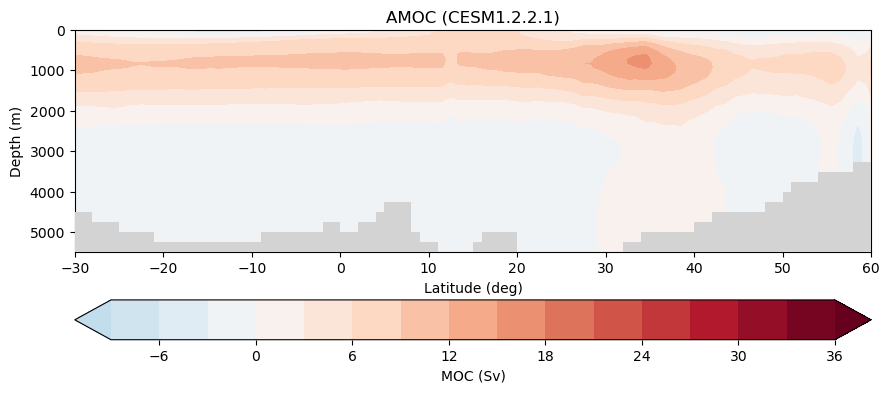

In [7]:
# Consolidated CESM1.2.2.1 variables and MOC pipeline (inserted)
import xarray as xr
import numpy as np
import numpy.ma as ma
from matplotlib.path import Path

# Paths (set in paths.py)
CESM122_DATASET_PATH = CESM122_PLIO_PATH
ICESM13_DATASET_PATH = ICESM13_PLIO_MOC_PATH
BASIN = 'atlantic'

# Load datasets
cesm122_ds = xr.open_dataset(CESM122_DATASET_PATH)
icesm13_ds = xr.open_dataset(ICESM13_DATASET_PATH)

# V (ensure we have a (depth,lat,lon) numpy array)
v_da = cesm122_ds['VVEL']
v_vals = v_da.values
if v_vals.ndim == 4:
    v_vals = v_vals[0, ...]
elif v_vals.ndim != 3:
    raise ValueError(f'Unexpected V array ndim: {v_vals.ndim}')
# Convert V from cm/s to m/s for transport calculations
v = v_vals / 100.0

# Coordinates / grid metrics
depth_1 = cesm122_ds['z_t'].values / 100.0    # cm -> m
latitude_1 = cesm122_ds['lat'].values
longitude_1 = cesm122_ds['lon'].values

dz_values = cesm122_ds['dz'].values / 100.0   # POP layer thickness, cm -> m
dz_3d = dz_values[:, np.newaxis, np.newaxis]
deg_to_m = 111195.0
dx_lat = 1 * deg_to_m * np.cos(np.deg2rad(latitude_1))
dx_2d = dx_lat[np.newaxis, :, np.newaxis]

# Helpers: longitude shift and Atlantic polygon masking
def shift_lon_to_continuous(lon_values):
    return ((np.asarray(lon_values) + 180.0) % 360.0) - 180.0

def apply_atlantic_mask_3d(array, lat, lon, depth):
    atlantic_polygon = Path([
        (-70, 70), (20, 70), (20, 50), (0, 50), (0, 40), (-5, 40),
        (-5, 20), (20, 20), (20, -90), (-70, -90),
        (-70, 12.8396), (-90, 12.8396), (-90, 50), (-70, 50)
    ])
    masked_slices = []
    points = np.column_stack((lon.flatten(), lat.flatten()))
    geographical_mask = atlantic_polygon.contains_points(points).reshape(lat.shape)
    for iz in range(len(depth)):
        slice_ = array[iz, :, :]
        if ma.isMaskedArray(slice_):
            original_mask = ma.getmask(slice_)
            combined_mask = np.logical_or(original_mask, ~geographical_mask)
            masked_slice = ma.masked_where(combined_mask, slice_)
        else:
            masked_slice = ma.masked_where(~geographical_mask, slice_)
        masked_slices.append(masked_slice)
    return ma.stack(masked_slices, axis=0)

# Create lat/lon meshes (lon shifted to -180..180)
lon_shifted = shift_lon_to_continuous(longitude_1)
lat_2d, lon_2d = np.meshgrid(latitude_1, lon_shifted, indexing='ij')

# Build geographic basin mask (geometry-only) and apply to V
mask_probe_3d = np.ones_like(v, dtype=np.float32)
v_masked_3d_all = apply_atlantic_mask_3d(mask_probe_3d, lat_2d, lon_2d, depth_1)
basin_mask_cesm122 = ~v_masked_3d_all.mask[0]    # 2D boolean (lat, lon)
v_masked_3d = apply_atlantic_mask_3d(v, lat_2d, lon_2d, depth_1)  # masked array (depth,lat,lon)

# Prepare numeric transport field (masked/NaN -> 0) and compute MOC
v_for_transport = np.nan_to_num(v_masked_3d.filled(0.0), nan=0.0)
transport = v_for_transport * dz_3d * dx_2d            # m^3/s (depth,lat,lon)
transport_zonal_sum = np.sum(transport, axis=2)       # (depth, lat)
moc_calc = np.cumsum(transport_zonal_sum, axis=0)     # cumulative from surface down (m^3/s)

# Extract latitudes inside basin and plotting slice
lat_in_basin = np.where(basin_mask_cesm122.any(axis=1))[0]
lat_basin = latitude_1[lat_in_basin]
moc_plot = moc_calc[:, lat_in_basin]
wet_cesm122 = np.isfinite(v_masked_3d.filled(np.nan)).any(axis=2)[:, lat_in_basin]
bathy_cesm122 = model_bathymetry_from_wet_cells(depth_1, wet_cesm122)
depth_bot_cesm122 = cesm122_ds['z_w_bot'].values / 100.0  # the cumulative sum applies at each layer's bottom

# Plot params (data-driven limits recommended)
plot_levels = np.arange(-9, 39, 3)
plot_vmin = np.nanmin(moc_plot / 1e6)
plot_vmax = np.nanmax(moc_plot / 1e6)
print('CESM1.2.2.1 plot vmin/vmax (Sv):', plot_vmin, plot_vmax)
# Plot CESM1.2.2.1 MOC (convert to Sv for plotting) with fixed color limits and latitude range
import matplotlib.pyplot as plt
moc_plot_masked = np.ma.masked_invalid(moc_plot / 1e6)
# Use the same plotting limits as other panels
vmin, vmax = -36.0, 36.0
cmap = plt.cm.get_cmap('RdBu_r')
# set under/over colors similar to other plots
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))
plt.figure(figsize=(9, 4))
levels = np.arange(-9, 39, 3)
plt.contourf(lat_basin, depth_bot_cesm122, moc_plot_masked, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
shade_below_model_bathymetry(plt.gca(), lat_basin, bathy_cesm122, depth_bot_cesm122.max())
cb = plt.colorbar(orientation='horizontal', label='MOC (Sv)')
# match latitude limits used elsewhere
plt.axis([float(lat_basin.min()), float(lat_basin.max()), float(depth_bot_cesm122.max()), 0])
plt.xlim(-30, 60)
plt.xlabel('Latitude (deg)')
plt.ylabel('Depth (m)')
plt.title('AMOC (CESM1.2.2.1)')
plt.tight_layout()
plt.show()
# Save plotting arrays for reuse in collated panels
moc_plot_cesm122 = moc_plot.copy()
moc_plot_masked_cesm122 = moc_plot_masked.copy()
lat_basin_cesm122 = lat_basin.copy()
depth_cesm122 = depth_bot_cesm122.copy()


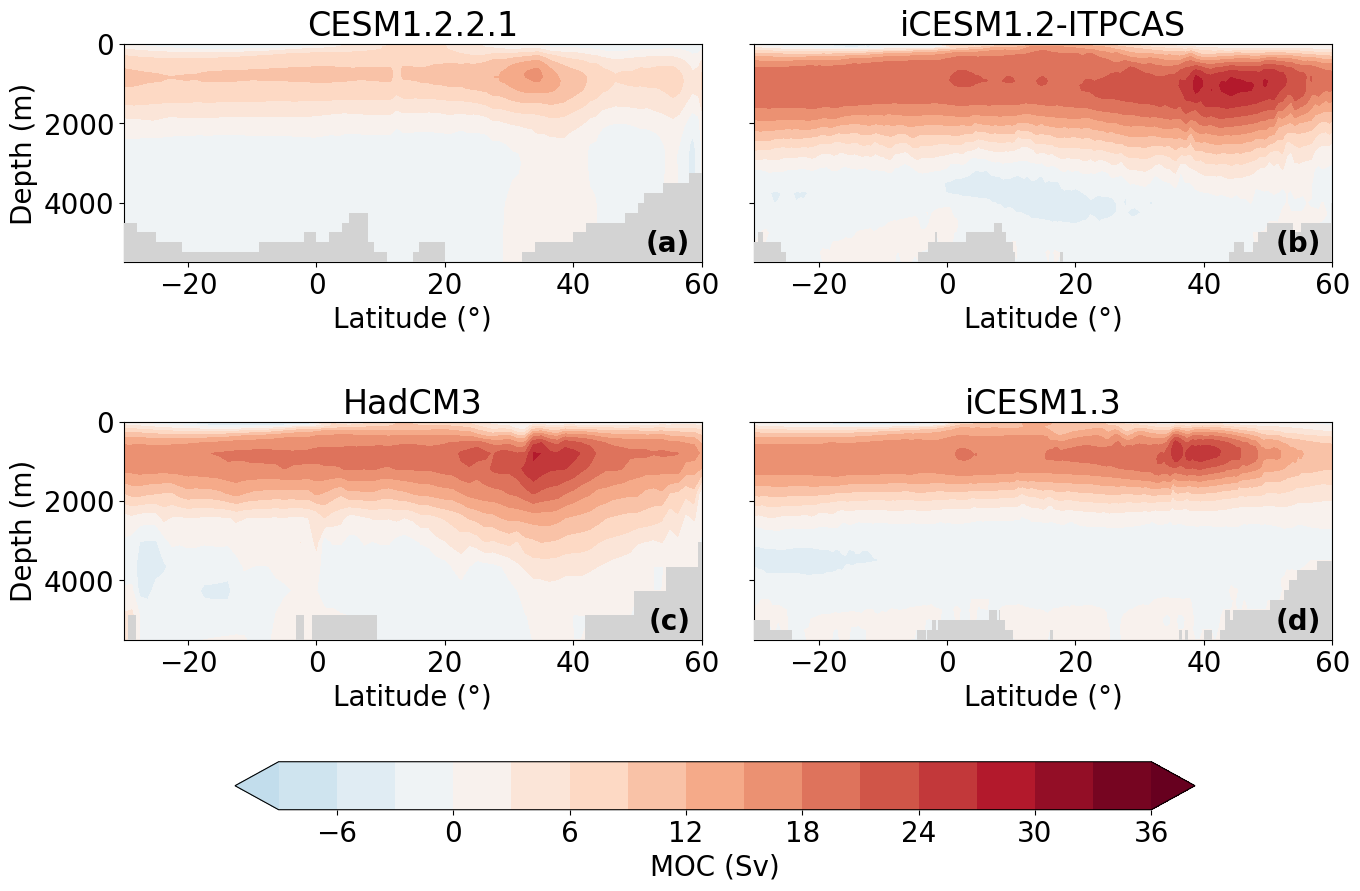

In [8]:
# 2x2 Collated MOC figure (CESM1.2.2.1, iCESM1.2-ITPCAS, HadCM3, iCESM1.3) with shared colorbar
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
import numpy.ma as ma

# Common colormap / levels (Sv)
vmin, vmax = -36.0, 36.0
levels = np.arange(-9, 39, 3)
cmap = plt.cm.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))


# Axis text sizes for publishing
plt.rcParams.update({
    "font.size": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
})

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
plt.subplots_adjust(left=0.10, right=0.95, bottom=0.12, top=0.92, wspace=0.12, hspace=0.22)
axes = axs.ravel()

# Unicode degree symbol
deg_sym = "\u00b0"

# Panel 1: CESM1.2.2.1
if 'lat_basin_cesm122' in globals() and 'depth_cesm122' in globals() and 'moc_plot_masked_cesm122' in globals():
    cs0 = axes[0].contourf(lat_basin_cesm122, depth_cesm122, moc_plot_masked_cesm122, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
else:
    cs0 = None
    axes[0].text(0.5, 0.5, 'CESM1.2.2.1 data unavailable', ha='center', va='center')
axes[0].set_title('CESM1.2.2.1')
axes[0].set_xlim(-30, 60)
axes[0].set_ylim(depth_cesm122.max() if 'depth_cesm122' in globals() else 1, 0)
axes[0].set_xlabel(f'Latitude ({deg_sym})')
axes[0].set_ylabel('Depth (m)')

# Panel 2: iCESM1.2-ITPCAS
cs1 = axes[1].contourf(lat_valid, z_bot_m, moc_valid, levels=np.arange(-9, 39, 3), cmap=cmap, vmin=-36, vmax=36, extend='both')
axes[1].set_title('iCESM1.2-ITPCAS')
axes[1].set_xlim(-30, 60)
axes[1].set_ylim(z_bot_m.max(), 0)
axes[1].set_xlabel(f'Latitude ({deg_sym})')

# Panel 3: HadCM3, force the exact working HADCM3 arrays when available
if 'lat_basin_hadcm3' in globals() and 'moc_plot_hadcm3' in globals():
    # For HadCM3 we require an explicit matching depth vector; do not fallback
    nlev = moc_plot_hadcm3.shape[0]
    depth_use = None
    hadcm3_candidates = ['depth_bot_hadcm3', 'depth_1_hadcm3', 'depth_hadcm3', 'depth_1']
    for candidate_name in hadcm3_candidates:
        if candidate_name in globals():
            try:
                candidate = globals()[candidate_name]
                cand_len = np.shape(candidate)[0] if hasattr(candidate, '__len__') else None
            except Exception:
                cand_len = None
            if cand_len == nlev:
                depth_use = candidate
                break
    if depth_use is None:
        axes[2].text(0.5, 0.5, 'HadCM3 depth mismatch or missing; HadCM3 data unavailable', ha='center', va='center')
    else:
        axes[2].contourf(
            lat_basin_hadcm3,
            depth_use,
            moc_plot_hadcm3 / 1e6,
            levels=np.arange(-9, 39, 3),
            cmap=cmap,
            vmin=-36,
            vmax=36,
            extend='both',
        )
else:
    axes[2].text(0.5, 0.5, 'HadCM3 data unavailable', ha='center', va='center')
axes[2].set_title('HadCM3')
axes[2].set_xlim(-30, 60)
# set_ylim using the matched depth vector if available
if 'depth_use' in locals() and depth_use is not None:
    axes[2].set_ylim(float(np.max(depth_use)), 0)
elif 'depth_1' in globals():
    axes[2].set_ylim(float(depth_1.max()), 0)
axes[2].set_xlabel(f'Latitude ({deg_sym})')

# Panel 4: iCESM1.3
# Prefer the computed icesm13_mocz_calc (time,z,lat) if available and reduce to 2D for plotting
if 'icesm13_mocz_calc' in globals() and 'icesm13_lats' in globals() and ('icesm13_z_t' in globals() or 'icesm13_z' in globals()):
    icesm13_z_use = icesm13_z_bot if 'icesm13_z_bot' in globals() else (icesm13_z_t if 'icesm13_z_t' in globals() else icesm13_z)
    moc_icesm13 = icesm13_mocz_calc.values if hasattr(icesm13_mocz_calc, 'values') else icesm13_mocz_calc
    if moc_icesm13.ndim == 3:
        moc_plot_icesm13 = moc_icesm13[0, :, :] / 1e6
    elif moc_icesm13.ndim == 2:
        moc_plot_icesm13 = moc_icesm13 / 1e6
    else:
        moc_plot_icesm13 = np.squeeze(moc_icesm13) / 1e6
    axes[3].contourf(icesm13_lats, icesm13_z_use, moc_plot_icesm13, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
else:
    axes[3].text(0.5, 0.5, 'iCESM1.3 data unavailable', ha='center', va='center')
axes[3].set_title('iCESM1.3')
axes[3].set_xlim(-30, 60)
# set_ylim from icesm13_z_use if available (defined when icesm13_mocz_calc plotting branch runs)
if 'icesm13_z_use' in locals():
    axes[3].set_ylim(float(np.max(icesm13_z_use)), 0)
elif 'icesm13_z_t' in globals():
    axes[3].set_ylim(float(np.max(icesm13_z_t)), 0)
else:
    axes[3].set_ylim(1, 0)
axes[3].set_xlabel(f'Latitude ({deg_sym})')
axes[2].set_ylabel('Depth (m)')

# Shared y-axis limits are final now; cover all depth below each model seafloor.
plot_bottom = axes[0].get_ylim()[0]
if cs0 is not None and 'bathy_cesm122' in globals():
    shade_below_model_bathymetry(axes[0], lat_basin_cesm122, bathy_cesm122, plot_bottom)
shade_below_model_bathymetry(axes[1], lat_valid, bathy_icesm12[valid_lat], plot_bottom)
if 'depth_use' in locals() and depth_use is not None and 'bathy_hadcm3' in globals():
    shade_below_model_bathymetry(axes[2], lat_basin_hadcm3, bathy_hadcm3, plot_bottom)
if 'icesm13_z_use' in locals() and 'bathy_icesm13' in globals():
    shade_below_model_bathymetry(axes[3], icesm13_lats, bathy_icesm13, plot_bottom)

for ax, label in zip(axes, ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.98, 0.02, label,
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=20, fontweight="bold",
        zorder=20,
    )

# shared colorbar below the panels
# Use cs0 or cs1 for colorbar depending on which is defined (since cs0 now may be None if CESM1.2.2.1 data is unavailable)
cb_plot = cs0 if cs0 is not None else cs1
cbar = fig.colorbar(
    cb_plot,
    ax=axes.ravel().tolist(),
    orientation='horizontal',
    fraction=0.06,
    pad=0.24,
)
cbar.set_label('MOC (Sv)')
plt.tight_layout(rect=[0, 0.26, 1, 0.95])
plt.show()


# Pre-industrial MOC (all four models)

Same method as the Pliocene cells above; run cell 1 (helpers) first. Notes:
- **iCESM1.2-ITPCAS 0ka** is on the standard gx1v6 grid, unlike Eoi400, so the Eoi400 REGION_MASK is mapped onto it by nearest ocean neighbour.
- **iCESM1.3 PI** file has no VVEL, so POP's Atlantic `MOC` (Eulerian mean + eddy-induced, equivalent to VVEL + VISOP) is plotted; bathymetry uses TEMP wet cells with the Pliocene REGION_MASK from the same grid.
- All PI variables carry a `_pi_` name, so the Pliocene variables are not overwritten.

In [9]:
import re
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from scipy.spatial import cKDTree

# Pre-industrial (PI) MOC for all four models
# -----------------------------
PI_ICESM12_PATH = ICESM12_PI_VVEL_PATH
PI_HADCM3_PATH = HADCM3_PI_VW_PATH
PI_ICESM13_PATH = ICESM13_PI_MOC_PATH
PI_CESM122_PATH = CESM122_PI_PATH
# Region masks borrowed from the Pliocene runs (the PI files do not ship their own)
ICESM13_PLIO_PATH = ICESM13_PLIO_MOC_PATH
BASIN_HADCM3_PATH = HADCM3_BASIN_PATH
NUM_TIME_STEPS_TO_AVERAGE = 12
EARTH_RADIUS_M = 6_371_000.0

def pop_atlantic(mask_da):
    return (mask_da > 5) | (mask_da == 1)

def regrid_region_mask_nearest(src_lat, src_lon, src_mask, dst_lat, dst_lon, dst_wet):
    """Give each wet destination cell the REGION_MASK value of the nearest ocean source cell."""
    def xyz(lat, lon):
        lat, lon = np.deg2rad(np.asarray(lat, float)), np.deg2rad(np.asarray(lon, float))
        return np.column_stack([(np.cos(lat) * np.cos(lon)).ravel(), (np.cos(lat) * np.sin(lon)).ravel(), np.sin(lat).ravel()])
    src_ocean = np.asarray(src_mask).ravel() != 0
    tree = cKDTree(xyz(src_lat, src_lon)[src_ocean])
    _, idx = tree.query(xyz(dst_lat, dst_lon))
    out = np.asarray(src_mask).ravel()[src_ocean][idx].reshape(np.shape(dst_lat))
    return np.where(dst_wet, out, 0)

# ---------- iCESM1.2-ITPCAS, 0ka ----------
# The 0ka run is on the standard gx1v6 grid, Eoi400 on a different grid, so its mask is mapped geographically.
icesm12_ds = xr.open_dataset(PI_ICESM12_PATH, use_cftime=True)
icesm12_mask_src = xr.open_dataset(ICESM12_PLIO_MASK_PATH)
icesm12_vvel = icesm12_ds['VVEL'] / 100.0
icesm12_z_t_m = icesm12_ds['z_t'].values / 100.0
icesm12_dz = xr.DataArray(np.diff(layer_edges_from_centres(icesm12_z_t_m)),
                     coords={'z_t': icesm12_ds['z_t']}, dims=('z_t',))
icesm12_lon_rad = np.deg2rad(icesm12_ds['ULONG'].values)
icesm12_lon_step = np.abs((np.roll(icesm12_lon_rad, -1, axis=1) - icesm12_lon_rad + np.pi) % (2 * np.pi) - np.pi)
icesm12_dx = xr.DataArray(EARTH_RADIUS_M * np.cos(np.deg2rad(icesm12_ds['ULAT'].values)) * icesm12_lon_step,
                     coords=icesm12_ds['ULAT'].coords, dims=icesm12_ds['ULAT'].dims)
icesm12_vvel_mean = icesm12_vvel.isel(time=slice(-NUM_TIME_STEPS_TO_AVERAGE, None)).mean(dim='time')
icesm12_wet_cells = (icesm12_vvel_mean.notnull() & (icesm12_vvel_mean != 0))
icesm12_region_mask = regrid_region_mask_nearest(icesm12_mask_src['TLAT'].values, icesm12_mask_src['TLONG'].values, icesm12_mask_src['REGION_MASK'].values,
                                            icesm12_ds['ULAT'].values, icesm12_ds['ULONG'].values, icesm12_wet_cells.any('z_t').values)
icesm12_mask = xr.DataArray(pop_atlantic(icesm12_region_mask), dims=('nlat', 'nlon'))
icesm12_transport = (icesm12_vvel_mean * icesm12_dz * icesm12_dx).fillna(0)
moc_pi_icesm12 = (icesm12_transport.where(icesm12_mask).sum(dim='nlon', skipna=True).cumsum(dim='z_t') / 1e6).values
icesm12_lat_1d = icesm12_ds['ULAT'].mean(dim='nlon').values
valid_lat_pi_icesm12 = np.isfinite(icesm12_lat_1d)
lat_pi_icesm12 = icesm12_lat_1d[valid_lat_pi_icesm12]
moc_pi_icesm12 = moc_pi_icesm12[:, valid_lat_pi_icesm12]
depth_pi_icesm12 = layer_edges_from_centres(icesm12_z_t_m)[1:]  # plot at layer bottoms
bathy_pi_icesm12 = model_bathymetry_from_wet_cells(icesm12_z_t_m, icesm12_wet_cells.where(icesm12_mask, False).any(dim='nlon').values)[valid_lat_pi_icesm12]
print(f"iCESM1.2-ITPCAS PI MOC: {np.nanmin(moc_pi_icesm12):.2f} to {np.nanmax(moc_pi_icesm12):.2f} Sv")

# ---------- HadCM3, PI ----------
hadcm3_pi_ds = xr.open_dataset(PI_HADCM3_PATH)
hadcm3_pi_v = hadcm3_pi_ds['field704'].values / 100.0
hadcm3_pi_z_t = hadcm3_pi_ds['depth_1'].values
hadcm3_pi_lat = hadcm3_pi_ds['latitude_1'].values
hadcm3_pi_lon = hadcm3_pi_ds['longitude_1'].values
hadcm3_pi_edges = np.concatenate([[0.0], hadcm3_pi_ds['depth'].values, [2 * hadcm3_pi_z_t[-1] - hadcm3_pi_ds['depth'].values[-1]]])
depth_pi_hadcm3 = hadcm3_pi_edges[1:]  # plot at layer bottoms
hadcm3_pi_dz = np.diff(hadcm3_pi_edges)  # true layer thickness from the W (layer-bottom) depths
hadcm3_pi_dx = (1.25 * 111195.0 * np.cos(np.deg2rad(hadcm3_pi_lat)))[None, :, None]

with open(BASIN_HADCM3_PATH, "r", encoding="utf-8", errors="ignore") as f:
    row_data = []
    for line in f:
        stripped = line.strip()
        if not stripped or stripped.startswith("C") or not re.match(r"^\d+", stripped):
            continue
        nums = [int(x) for x in re.findall(r"-?\d+", stripped)]
        if len(nums) >= 17:
            row_data.append((nums[0], nums[1:17]))
n_rows_file = max(r for r, _ in row_data)
mask_file = np.zeros((n_rows_file, 288), dtype=bool)
for row_id, vals in row_data:
    segs = vals[8:12]  # Atlantic = basin index 3
    for s, e in [(segs[0], segs[1]), (segs[2], segs[3])]:
        if s <= 0 or e <= 0:
            continue
        s0, e0 = max(0, s - 1), min(287, e - 1)
        if e0 >= s0:
            mask_file[row_id - 1, s0:e0 + 1] = True
        else:
            mask_file[row_id - 1, s0:] = True
            mask_file[row_id - 1, :e0 + 1] = True
row_map = np.round(np.linspace(0, n_rows_file - 1, len(hadcm3_pi_lat))).astype(int)
hadcm3_pi_mask = mask_file[row_map, :len(hadcm3_pi_lon)]

hadcm3_pi_transport = np.nan_to_num(np.where(hadcm3_pi_mask[None], hadcm3_pi_v, 0.0), nan=0.0) * hadcm3_pi_dz[:, None, None] * hadcm3_pi_dx
hadcm3_pi_moc = np.cumsum(hadcm3_pi_transport.sum(axis=2), axis=0) / 1e6
hadcm3_pi_lat_idx = np.where(hadcm3_pi_mask.any(axis=1))[0]
lat_pi_hadcm3 = hadcm3_pi_lat[hadcm3_pi_lat_idx]
moc_pi_hadcm3 = hadcm3_pi_moc[:, hadcm3_pi_lat_idx]
bathy_pi_hadcm3 = model_bathymetry_from_wet_cells(
    hadcm3_pi_z_t, (np.isfinite(hadcm3_pi_v) & hadcm3_pi_mask[None]).any(axis=2)[:, hadcm3_pi_lat_idx])
print(f"HadCM3 PI MOC: {moc_pi_hadcm3.min():.2f} to {moc_pi_hadcm3.max():.2f} Sv")

# ---------- iCESM1.3, PI ----------
# This file has no VVEL, so use POP's own Atlantic MOC: Eulerian mean + eddy-induced (= VVEL + VISOP used for the Pliocene).
icesm13_pi_ds = xr.open_dataset(PI_ICESM13_PATH, decode_times=False)
icesm13_pi_moc_all = icesm13_pi_ds['MOC'].isel(time=0, transport_reg=1)
moc_pi_icesm13 = (icesm13_pi_moc_all.isel(moc_comp=0) + icesm13_pi_moc_all.isel(moc_comp=1)).values
depth_pi_icesm13 = icesm13_pi_ds['moc_z'].values / 100.0
lat_pi_icesm13 = icesm13_pi_ds['lat_aux_grid'].values
# Bathymetry: wet cells from TEMP, Atlantic cells from the Pliocene REGION_MASK on the same grid
icesm13_plio_ds = xr.open_dataset(ICESM13_PLIO_PATH, decode_times=False)
icesm13_pi_wet = np.isfinite(icesm13_pi_ds['TEMP'].values[0])
icesm13_pi_region = regrid_region_mask_nearest(icesm13_plio_ds['TLAT'].values, icesm13_plio_ds['TLONG'].values, icesm13_plio_ds['REGION_MASK'].values,
                                          icesm13_pi_ds['TLAT'].values, icesm13_pi_ds['TLONG'].values, icesm13_pi_wet.any(axis=0))
icesm13_pi_atl = pop_atlantic(icesm13_pi_region)
icesm13_pi_z_t = icesm13_pi_ds['z_t'].values / 100.0
icesm13_pi_tlat = icesm13_pi_ds['TLAT'].values
# Bin wet Atlantic columns onto lat_aux_grid
icesm13_pi_bin = np.digitize(icesm13_pi_tlat, lat_pi_icesm13) - 1
icesm13_pi_wet_by_lat = np.zeros((icesm13_pi_z_t.size, lat_pi_icesm13.size), dtype=bool)
for k in range(icesm13_pi_z_t.size):
    sel = icesm13_pi_wet[k] & icesm13_pi_atl & (icesm13_pi_bin >= 0) & (icesm13_pi_bin < lat_pi_icesm13.size)
    icesm13_pi_wet_by_lat[k, np.unique(icesm13_pi_bin[sel])] = True
bathy_pi_icesm13 = model_bathymetry_from_wet_cells(icesm13_pi_z_t, icesm13_pi_wet_by_lat)
print(f"iCESM1.3 PI MOC: {np.nanmin(moc_pi_icesm13):.2f} to {np.nanmax(moc_pi_icesm13):.2f} Sv")

# ---------- CESM1.2.2.1, PI ----------
cesm122_pi_ds = xr.open_dataset(PI_CESM122_PATH)
cesm122_pi_v = cesm122_pi_ds['VVEL'].values
cesm122_pi_v = (cesm122_pi_v[0] if cesm122_pi_v.ndim == 4 else cesm122_pi_v) / 100.0
cesm122_pi_z_t = cesm122_pi_ds['z_t'].values / 100.0
depth_pi_cesm122 = cesm122_pi_ds['z_w_bot'].values / 100.0  # plot at layer bottoms
cesm122_pi_lat = cesm122_pi_ds['lat'].values
cesm122_pi_lon = cesm122_pi_ds['lon'].values
cesm122_pi_dz = cesm122_pi_ds['dz'].values / 100.0  # POP layer thickness, cm -> m
cesm122_pi_dx = 111195.0 * np.cos(np.deg2rad(cesm122_pi_lat))
atlantic_polygon = Path([
    (-70, 70), (20, 70), (20, 50), (0, 50), (0, 40), (-5, 40),
    (-5, 20), (20, 20), (20, -90), (-70, -90),
    (-70, 12.8396), (-90, 12.8396), (-90, 50), (-70, 50)
])
cesm122_lat_2d, cesm122_lon_2d = np.meshgrid(cesm122_pi_lat, (cesm122_pi_lon + 180.0) % 360.0 - 180.0, indexing='ij')
cesm122_pi_mask = atlantic_polygon.contains_points(np.column_stack((cesm122_lon_2d.ravel(), cesm122_lat_2d.ravel()))).reshape(cesm122_lat_2d.shape)
cesm122_pi_transport = np.nan_to_num(np.where(cesm122_pi_mask[None], cesm122_pi_v, 0.0), nan=0.0) * cesm122_pi_dz[:, None, None] * cesm122_pi_dx[None, :, None]
cesm122_pi_moc = np.cumsum(cesm122_pi_transport.sum(axis=2), axis=0) / 1e6
cesm122_pi_lat_idx = np.where(cesm122_pi_mask.any(axis=1))[0]
lat_pi_cesm122 = cesm122_pi_lat[cesm122_pi_lat_idx]
moc_pi_cesm122 = np.ma.masked_invalid(cesm122_pi_moc[:, cesm122_pi_lat_idx])
bathy_pi_cesm122 = model_bathymetry_from_wet_cells(
    cesm122_pi_z_t, (np.isfinite(cesm122_pi_v) & cesm122_pi_mask[None]).any(axis=2)[:, cesm122_pi_lat_idx])
print(f"CESM1.2.2.1 PI MOC: {moc_pi_cesm122.min():.2f} to {moc_pi_cesm122.max():.2f} Sv")


iCESM1.2-ITPCAS PI MOC: -57.22 to 35.59 Sv
HadCM3 PI MOC: -48.45 to 137.26 Sv
iCESM1.3 PI MOC: -5.61 to 24.61 Sv
CESM1.2.2.1 PI MOC: -19.17 to 107.28 Sv


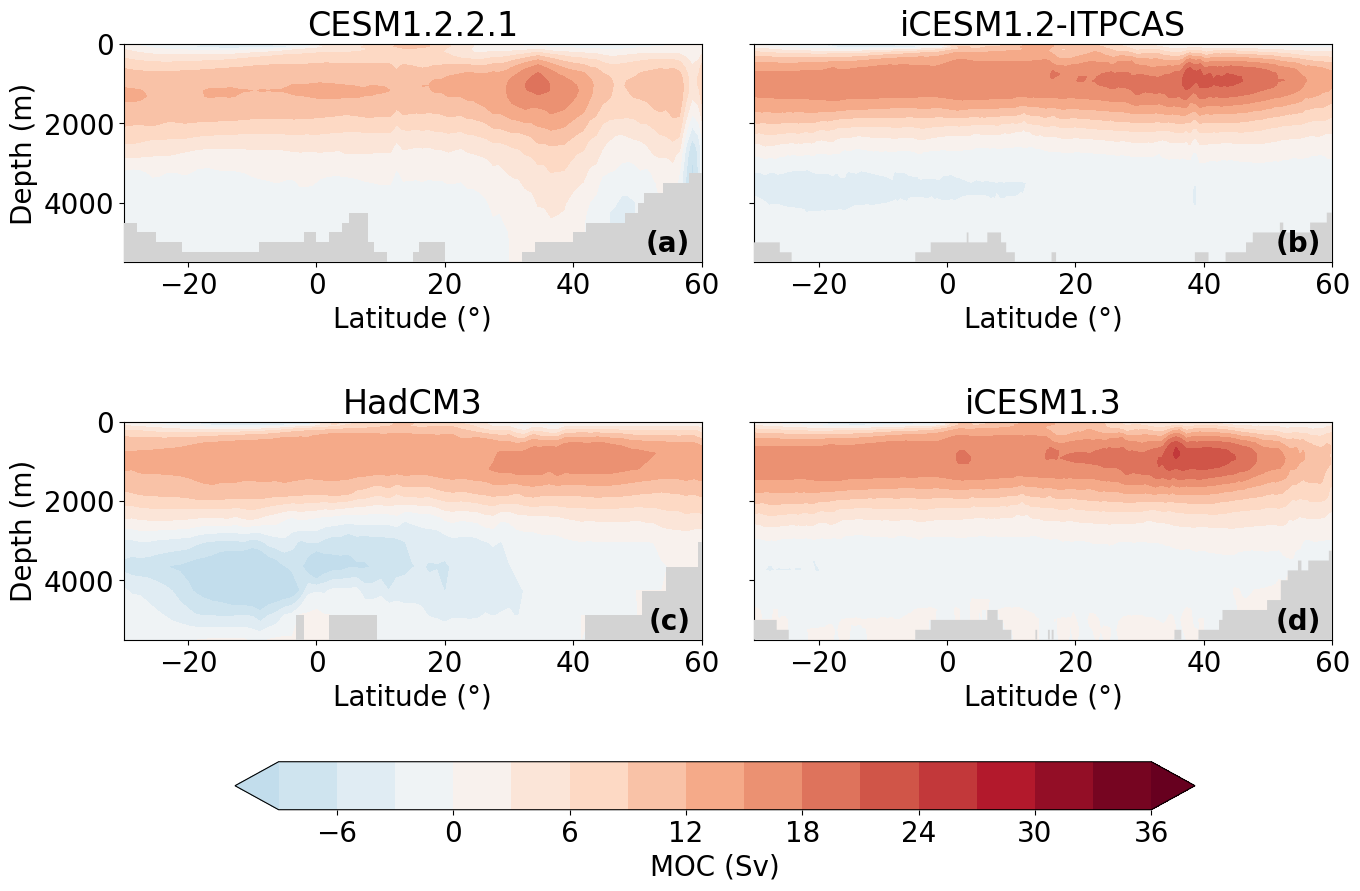

In [10]:
# 2x2 collated PI figure (same layout as moc_2x2.png) ----------
vmin, vmax = -36.0, 36.0
levels = np.arange(-9, 39, 3)
cmap = plt.cm.get_cmap('RdBu_r').copy()
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))
plt.rcParams.update({"font.size": 20, "axes.labelsize": 20, "xtick.labelsize": 20, "ytick.labelsize": 20})

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
plt.subplots_adjust(left=0.10, right=0.95, bottom=0.12, top=0.92, wspace=0.12, hspace=0.22)
axes = axs.ravel()
deg_sym = "\u00b0"
pi_panels = [
    ('CESM1.2.2.1', lat_pi_cesm122, depth_pi_cesm122, moc_pi_cesm122, bathy_pi_cesm122),
    ('iCESM1.2-ITPCAS', lat_pi_icesm12, depth_pi_icesm12, moc_pi_icesm12, bathy_pi_icesm12),
    ('HadCM3', lat_pi_hadcm3, depth_pi_hadcm3, moc_pi_hadcm3, bathy_pi_hadcm3),
    ('iCESM1.3', lat_pi_icesm13, depth_pi_icesm13, moc_pi_icesm13, bathy_pi_icesm13),
]
cs_pi = []
for ax, (title, lat, depth, moc, _) in zip(axes, pi_panels):
    cs_pi.append(ax.contourf(lat, depth, moc, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, extend='both'))
    ax.set_title(title)
    ax.set_xlim(-30, 60)
    ax.set_xlabel(f'Latitude ({deg_sym})')
axes[0].set_ylim(float(np.max(depth_pi_cesm122)), 0)
axes[0].set_ylabel('Depth (m)')
axes[2].set_ylabel('Depth (m)')

# Shared y-axis limits are final now; cover all depth below each model seafloor.
plot_bottom = axes[0].get_ylim()[0]
for ax, (_, lat, _, _, bathy) in zip(axes, pi_panels):
    shade_below_model_bathymetry(ax, lat, bathy, plot_bottom)

for ax, label in zip(axes, ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(0.98, 0.02, label, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=20, fontweight="bold", zorder=20)

cbar = fig.colorbar(cs_pi[0], ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.06, pad=0.24)
cbar.set_label('MOC (Sv)')
plt.tight_layout(rect=[0, 0.26, 1, 0.95])
plt.show()


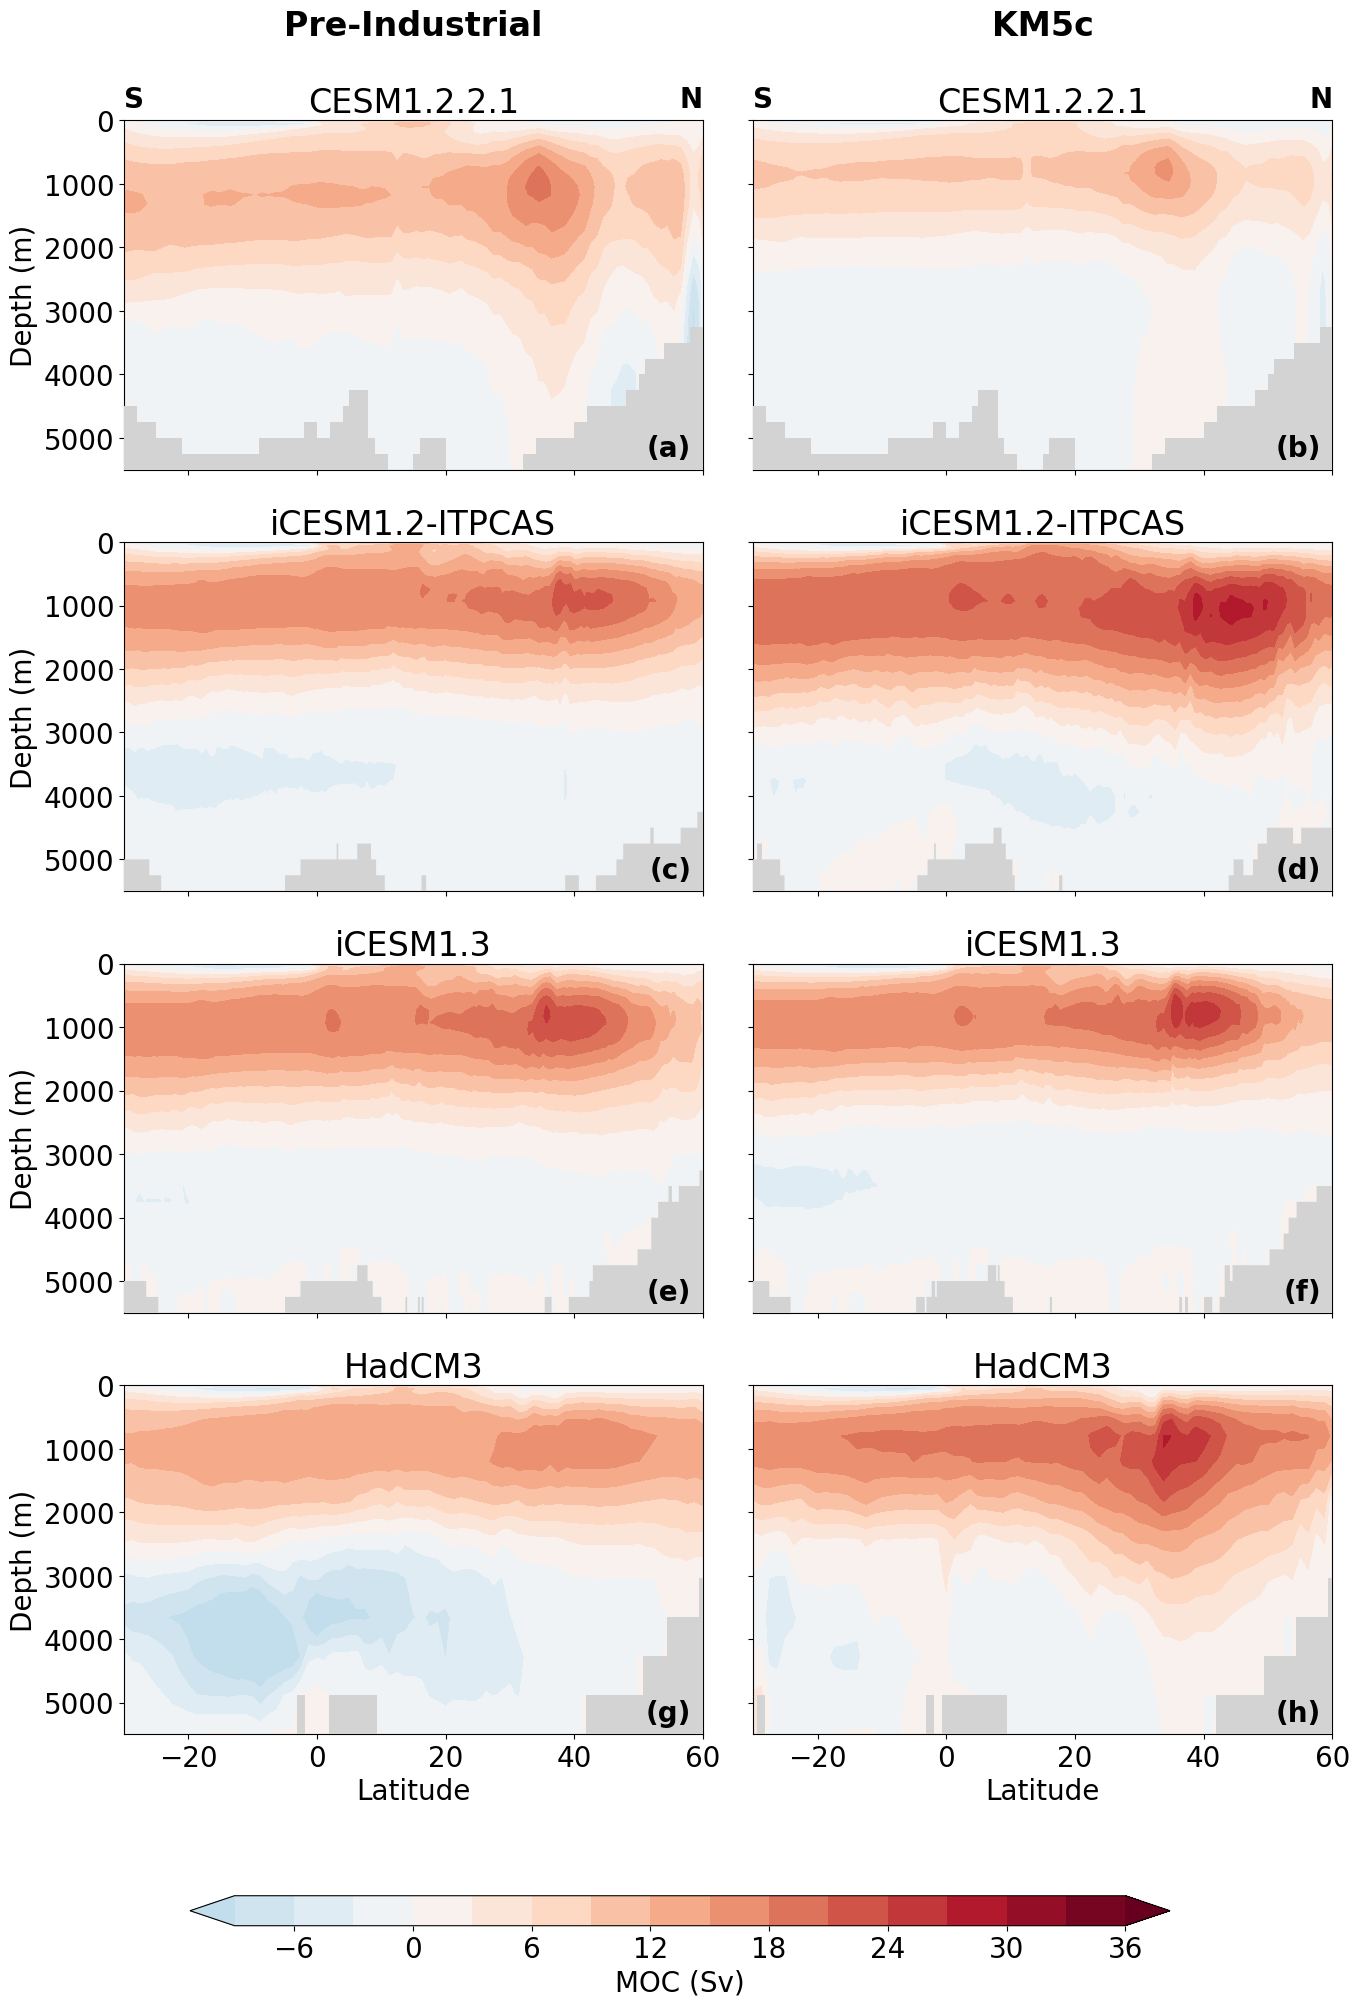

In [11]:
# Combined PI (left) and Pliocene (right) MOC figure, one model per row
icesm13_valid = ~np.isnan(icesm13_lats.values)
combined_rows = [
    ('CESM1.2.2.1',
     (lat_pi_cesm122, depth_pi_cesm122, moc_pi_cesm122, bathy_pi_cesm122),
     (lat_basin_cesm122, depth_cesm122, moc_plot_masked_cesm122, bathy_cesm122)),
    ('iCESM1.2-ITPCAS',
     (lat_pi_icesm12, depth_pi_icesm12, moc_pi_icesm12, bathy_pi_icesm12),
     (lat_valid, z_bot_m, moc_valid, bathy_icesm12[valid_lat])),
    ('iCESM1.3',
     (lat_pi_icesm13, depth_pi_icesm13, moc_pi_icesm13, bathy_pi_icesm13),
     (icesm13_lats.values[icesm13_valid], icesm13_z_bot, icesm13_mocz_calc[0, :, icesm13_valid].values / 1e6, bathy_icesm13[icesm13_valid])),
    ('HadCM3',
     (lat_pi_hadcm3, depth_pi_hadcm3, moc_pi_hadcm3, bathy_pi_hadcm3),
     (lat_basin_hadcm3, depth_bot_hadcm3, moc_plot_hadcm3 / 1e6, bathy_hadcm3)),
]

vmin, vmax = -36.0, 36.0
levels = np.arange(-9, 39, 3)
cmap = plt.cm.get_cmap('RdBu_r').copy()
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap.set_under(cmap(norm(-9)))
cmap.set_over(cmap(norm(36)))
plt.rcParams.update({"font.size": 20, "axes.labelsize": 20, "xtick.labelsize": 20, "ytick.labelsize": 20})
deg_sym = "\u00b0"

fig, axs = plt.subplots(4, 2, figsize=(14, 20), sharex=True, sharey=True)
plot_bottom = max(float(np.max(d)) for _, pi, plio in combined_rows for _, d, _, _ in (pi, plio))
cs = None
for row, (model, pi, plio) in enumerate(combined_rows):
    for col, (lat, depth, moc, bathy) in enumerate((pi, plio)):
        ax = axs[row, col]
        cs = ax.contourf(lat, depth, moc, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
        ax.set_xlim(-30, 60)
        ax.set_ylim(plot_bottom, 0)
        shade_below_model_bathymetry(ax, lat, bathy, plot_bottom)
        ax.set_title(model)
    axs[row, 0].set_ylabel('Depth (m)')
for ax in axs[-1]:
    ax.set_xlabel('Latitude')
for ax, label in zip(axs.ravel(), ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)"]):
    ax.text(0.98, 0.02, label, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=20, fontweight="bold", zorder=20)

# Mark the south / north ends of the latitude axis above the top row
for ax in axs[0]:
    ax.text(0.0, 1.02, 'S', transform=ax.transAxes, ha='left', va='bottom', fontsize=20, fontweight='bold')
    ax.text(1.0, 1.02, 'N', transform=ax.transAxes, ha='right', va='bottom', fontsize=20, fontweight='bold')

plt.tight_layout(rect=[0, 0.07, 1, 0.96], h_pad=1.2, w_pad=1.0)
for ax, heading in zip(axs[0], ['Pre-Industrial', 'KM5c']):
    fig.text((ax.get_position().x0 + ax.get_position().x1) / 2, 0.975, heading,
             ha='center', va='center', fontsize=24, fontweight='bold')
cax = fig.add_axes([0.15, 0.025, 0.7, 0.015])
cbar = fig.colorbar(cs, cax=cax, orientation='horizontal')
cbar.set_label('MOC (Sv)')
plt.savefig(FIG_DIR / 'moc_PI_Pliocene_4x2.png', dpi=300, bbox_inches='tight')
plt.show()
